# Uitgevoerde pilotanalyse — dedicated MX E4M3/A32

**Echte SVHN-training · 22 oktober 2026 · vijf afgeronde epochs · runstatus PASS**

Deze analyse gebruikt de door de gebruiker aangeleverde feedbackbundel van de dedicated E4M3/A32-proef, pakketversie `mx_e4m3_dedicated_pilot5_v2`. De oorspronkelijke bestanden zijn ongewijzigd opgenomen in `raw/`. De onderstaande uitkomsten en figuren zijn berekend uit de opgeslagen JSON/CSV; er is voor deze analyse geen training gestart en geen checkpoint geladen.

**Belangrijkste uitkomst:** de testaccuracy stijgt van **87,6998%** naar **93,1392%**. Het beste en het laatste checkpoint vallen beide op **epoch 5**. De gemeten tijdsbasis geeft voor een nieuwe honderd-epochrun een schatting van **41 minuten 53 seconden**. **Epoch100 is nog niet uitgevoerd; er is geen eindaccuracy beschikbaar.**

De figuren zijn eveneens beschikbaar als PNG in `figures/`. Voor opnieuw uitvoeren: gebruik deze notebookmap als werkmap. De portable parameter hieronder verwijst naar de meegeleverde ruwe resultaten.


In [1]:
from pathlib import Path
RUN_DIR = Path('raw')
SAVE_FIGURES = False  # Meegeleverde PNG's staan in figures/; heranalyse schrijft standaard niets.


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.dont_write_bytecode = True
if not (RUN_DIR / 'run_report.json').is_file():
    raise FileNotFoundError('Open de notebook vanuit de map pilot5_analysis; RUN_DIR moet naar de meegeleverde map raw verwijzen.')

# Laad exact de meegeleverde analysehelper; geen eerder geïmporteerde helper uit een andere run.
helper_path = RUN_DIR.resolve() / 'notebook_support.py'
helper_name = 'e4m3_saved_pilot_analysis_support'
spec = importlib.util.spec_from_file_location(helper_name, helper_path)
ns = importlib.util.module_from_spec(spec)
sys.modules[helper_name] = ns
spec.loader.exec_module(ns)

run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(Markdown('### Meldingen en ontbrekende gegevens'))
display(ns.diagnostics_table(run))


### Opgeslagen SVHN-run — herkomst volgens het runrapport

Runstatus: **PASS** · Analysefouten: **0**. Laatste ingelezen testepoch: **5**.

**Epoch100 niet uitgevoerd; geen eindresultaat.** Vijf epochs beoordelen techniek, eerste leergedrag en looptijd.

Deze analyse leest uitsluitend opgeslagen JSON/CSV. Zij start geen training en laadt geen model of checkpoint.

Onderdeel,Opgeslagen configuratie
Gewichtsformaat,MXFP8_E4M3
Activaties,A32
Updatemaster,float32
Model,"svhnq, expand=2"
Data,svhn; train-split=train; extra=False
Train / test,73257 / 26032
Groepsgrootte / schaal,32 / E8M0
Batch / seed,128 / 20261009
Afgeronde epochs,5
Beste checkpoint,first strict maximum of active-mode official-test top1


### Meldingen en ontbrekende gegevens

Niveau,Melding
RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)


## Checkpointselectie: beste = laatste = epoch 5

De selectie neemt het **eerste strikte maximum van de E4M3-testaccuracy**. Een gelijke score vervangt het eerdere beste checkpoint niet. De testaccuracy stijgt in iedere gemeten epoch; daarom zijn het beste en het laatste checkpoint hier dezelfde toestand van epoch 5. Beide rapporteren **24.246 / 26.032 correcte voorspellingen** en dezelfde checkpoint-SHA256. De twee balken stellen dus geen onafhankelijke trainingen voor.

De officiële testset is volgens het bestaande protocol gebruikt voor selectie. De beste score is daarom **geen onafhankelijke testschatting na selectie**. Bij een volledige latere run blijft epoch100 het vaste hoofdvergelijkingspunt; de beste epoch blijft apart weergegeven.


Controlepunt,Epoch,Testaccuracy [%],Correct / n,CE-loss,Selectiebron,Checkpoint
Laatste epoch,5,93.139213,24.246 / 26.032,0.235969,checkpoint_selection.json,last_checkpoint.pt
Beste E4M3-checkpoint,5,93.139213,24.246 / 26.032,0.235969,checkpoint_selection.json,best_checkpoint.pt
Vast eindpunt epoch100,100,NaN,—,NaN,niet uitgevoerd / niet beschikbaar,vast epochnummer; geen nieuwe selectie


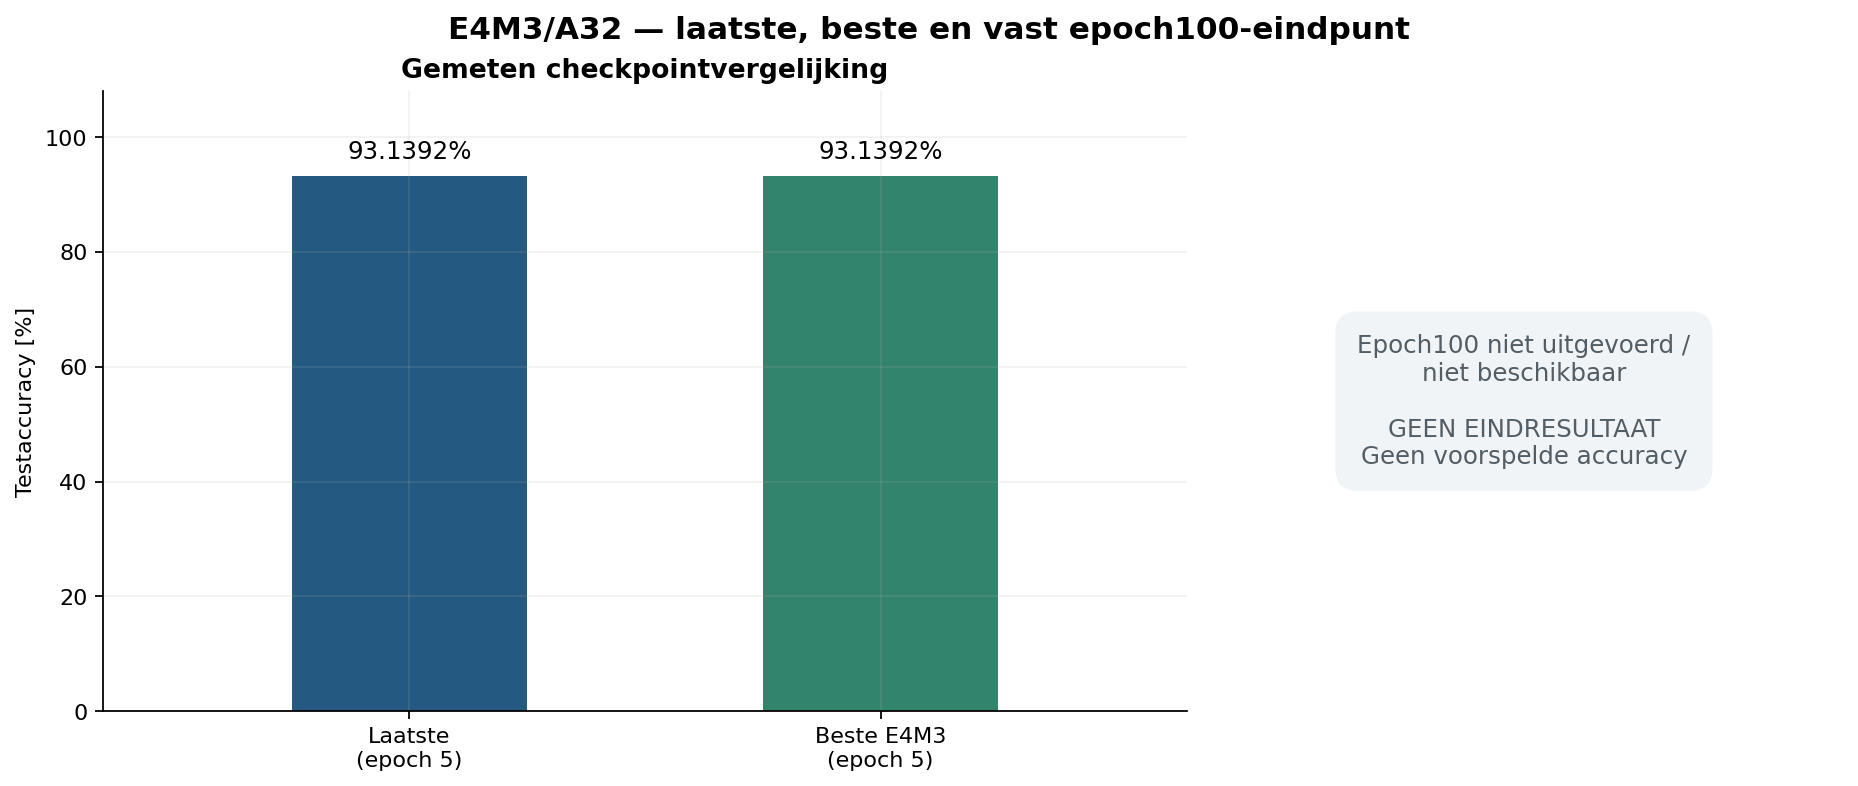

In [3]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'CE-loss': 8}))
figures['checkpoint_accuracy'] = ns.plot_checkpoint_accuracy(run)
display(figures['checkpoint_accuracy'])
plt.close(figures['checkpoint_accuracy'])


## Leercurves

Trainaccuracy en trainloss zijn tijdens de updates verzameld; testmetrics zijn na de epoch met bevroren evaluatiestaat gemeten. De figuur toont uitsluitend gemeten epochs.

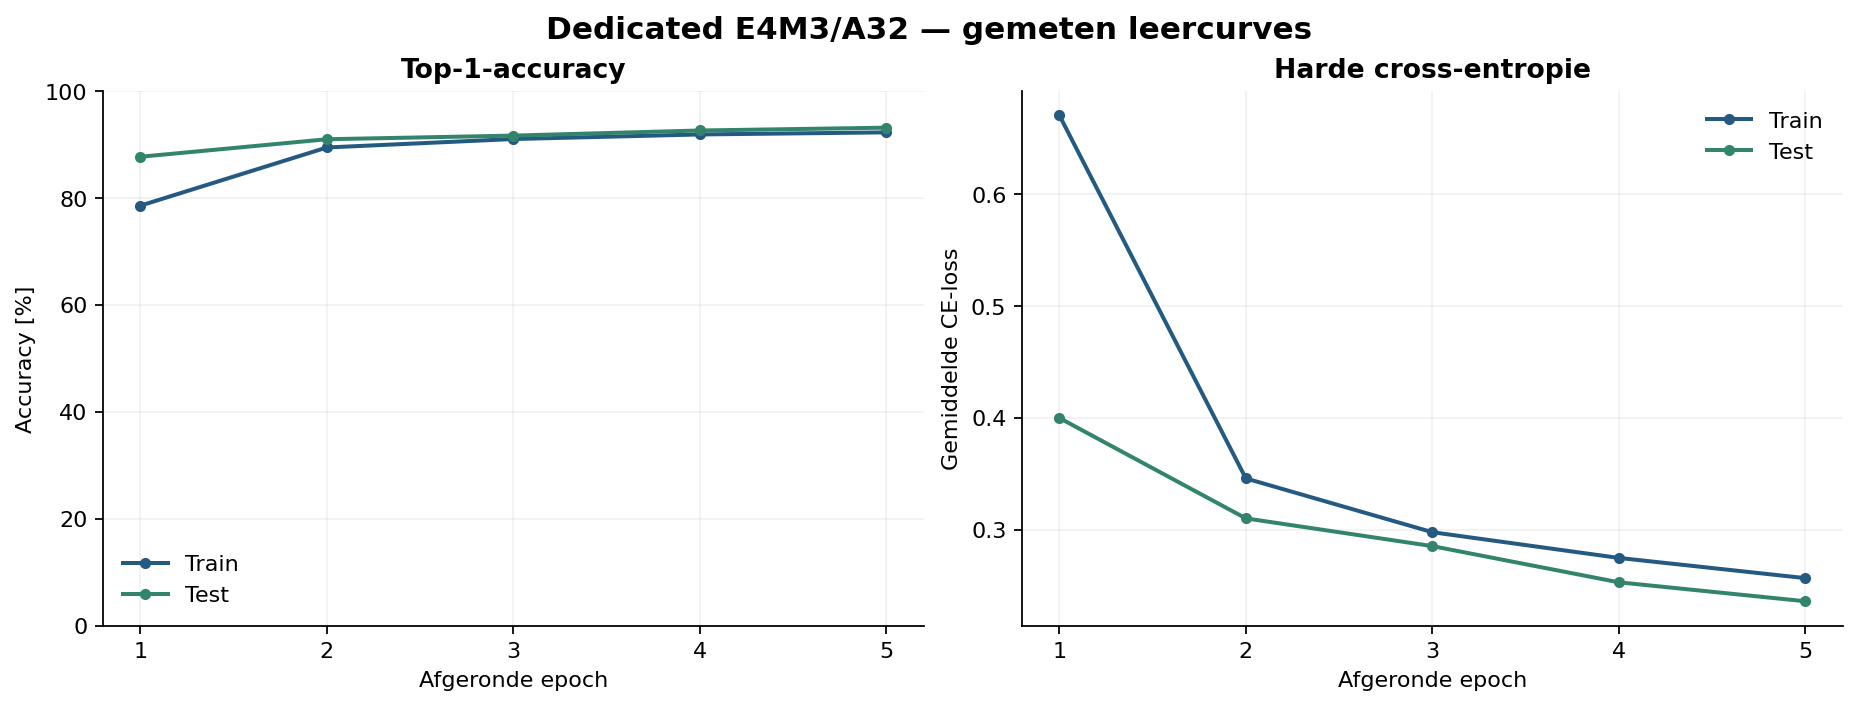

In [4]:
display(Markdown('## Leercurves\n\nTrainaccuracy en trainloss zijn tijdens de updates verzameld; testmetrics zijn na de epoch met bevroren evaluatiestaat gemeten. De figuur toont uitsluitend gemeten epochs.'))
figures['learning_curves'] = ns.plot_learning(run)
display(figures['learning_curves'])
plt.close(figures['learning_curves'])


## Looptijd en schatting voor een nieuwe training van 100 epochs

Warme epochs volgens het tijdsrapport: **[2, 3, 4, 5]**; mediaan: **25.1 s**. De schatting geldt voor een **nieuwe run van 100 epochs vanaf initialisatie**, niet voor het hervatten van deze pilot. De eerste gemeten epoch wordt apart geteld; het waargenomen minimum/maximum van de warme epochs levert alleen een scenario-bereik. Dit is geen statistisch betrouwbaarheidsinterval. Download, installatie, data-inladen en eindrapportage zijn niet inbegrepen. Vijf epochs meten geen langdurige thermische vertraging of LR-overgangen op epochs50/75/90. Er wordt **geen accuracy voor epoch100 voorspeld**.

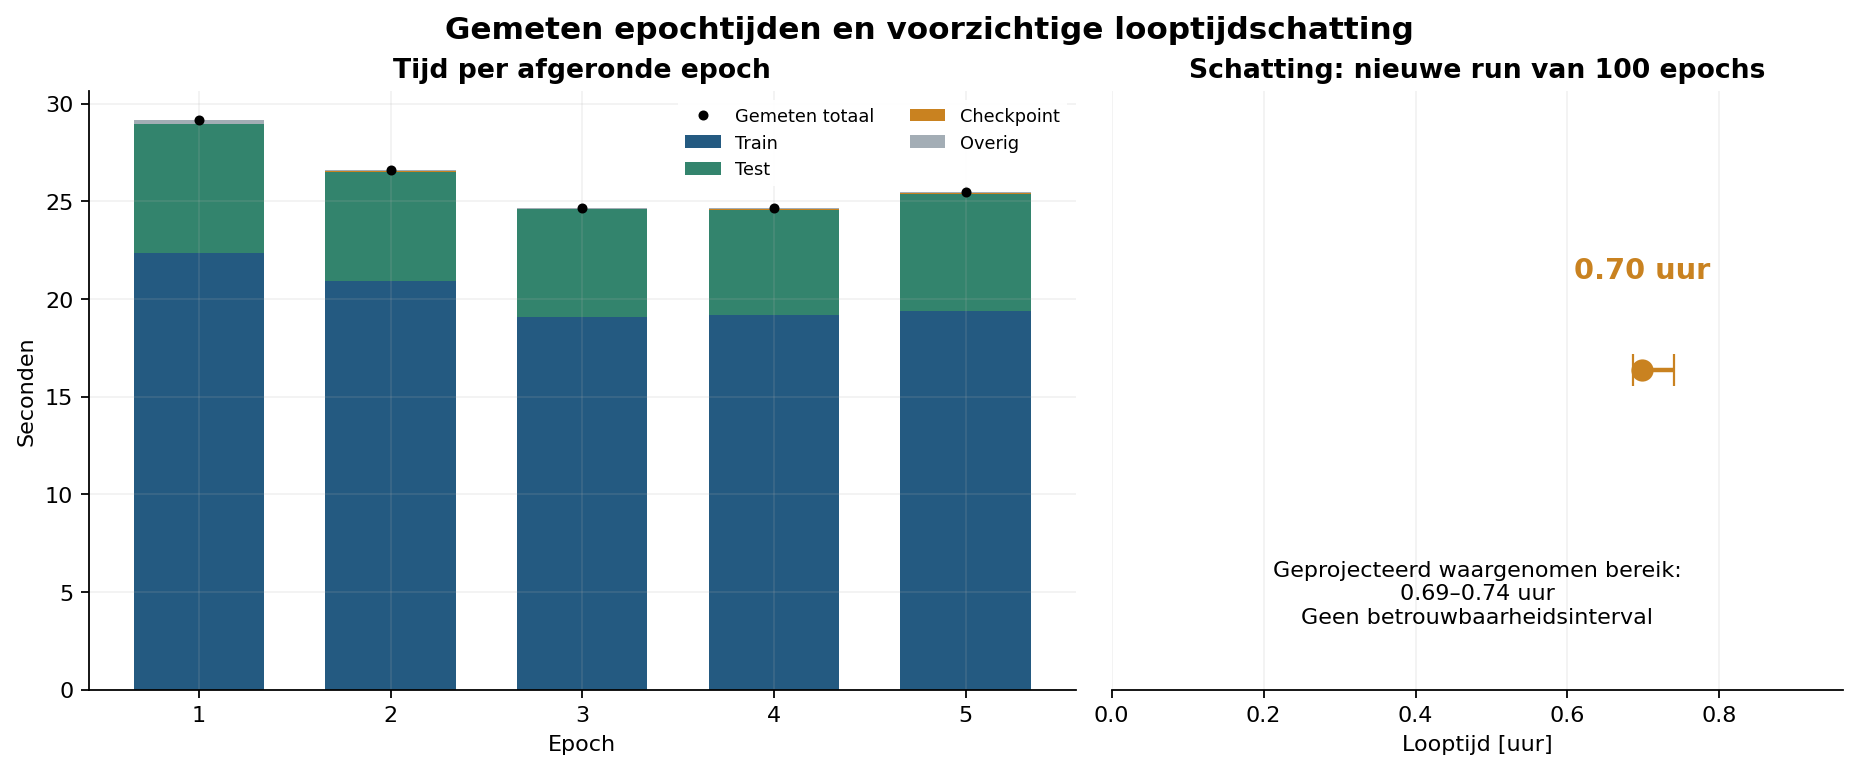

In [5]:
display(Markdown('## Looptijd en schatting voor een nieuwe training van 100 epochs'))
display(Markdown(ns.timing_markdown(run)))
figures['timing'] = ns.plot_timing(run)
display(figures['timing'])
plt.close(figures['timing'])


## GPU-geheugen

Toegewezen en gereserveerd geheugen zijn de opgeslagen pieken van de PyTorch CUDA-allocator. Dit is geen meting van alle GPU-processen en geen bewijs van compacte native MX-uitvoering. Ontbrekende metingen blijven ontbrekend.

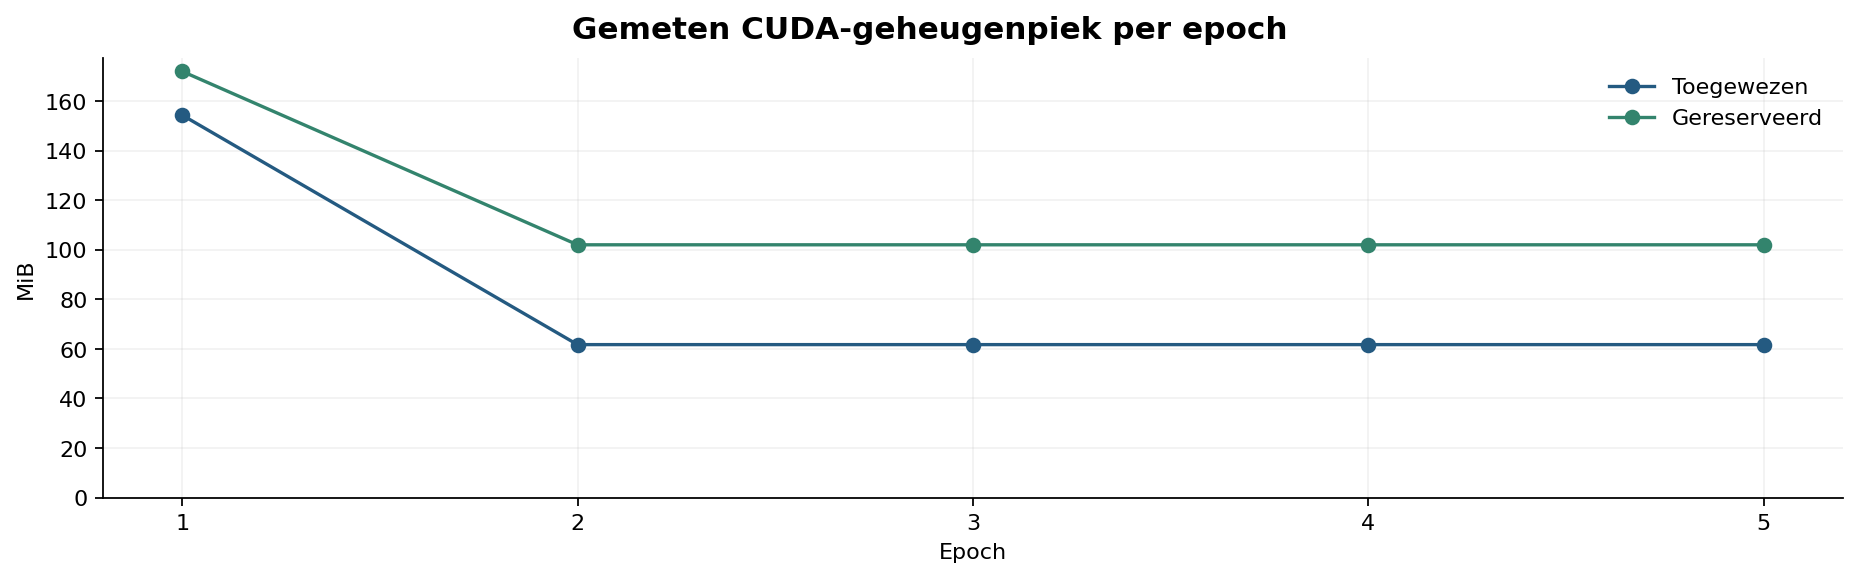

In [6]:
display(Markdown('## GPU-geheugen\n\nToegewezen en gereserveerd geheugen zijn de opgeslagen pieken van de PyTorch CUDA-allocator. Dit is geen meting van alle GPU-processen en geen bewijs van compacte native MX-uitvoering. Ontbrekende metingen blijven ontbrekend.'))
figures['gpu_memory'] = ns.plot_memory(run)
display(figures['gpu_memory'])
plt.close(figures['gpu_memory'])


In [7]:
display(Markdown('## Opgeslagen technische controles'))
display(Markdown('Deze tabel rapporteert controles uit de run; het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.'))
display(ns.audit_table(run))
display(Markdown('### Gewichtsupdates per epoch en doellaag'))
display(ns.weight_update_table(run))

display(Markdown('### Gewichtsdiagnostiek van de export op epoch 5'))
export_rows = pd.read_csv(RUN_DIR / 'mx_export_layers_best.csv')
export_last = pd.read_csv(RUN_DIR / 'mx_export_layers_last.csv')
if not export_rows.equals(export_last):
    raise ValueError('Best- en last-exportdiagnostiek verschillen terwijl het geselecteerde checkpoint gelijk is.')
n_weights = int(export_rows['n_weights'].sum())
outside = int(export_rows['out_of_element_range_before_round'].sum())
rel_min = float(export_rows['relative_l2'].min()) * 100
rel_max = float(export_rows['relative_l2'].max()) * 100
export_table = pd.DataFrame([
    ('MX-gewichten in zes doellagen', n_weights),
    ('Blokken / paddingposities', f"{int(export_rows['blocks'].sum())} / {int(export_rows['padded_slots'].sum())}"),
    ('Buiten lokaal elementbereik vóór afronding', f'{outside} / {n_weights} = {100 * outside / n_weights:.4f}%'),
    ('Relatieve L2-kwantisatiefout per laag', f'{rel_min:.4f}% – {rel_max:.4f}%'),
    ('Blokken met schaal begrensd aan E8M0-bereik', int(export_rows['scale_range_clamped_blocks'].sum())),
    ('Nieuw ontstane nulwaarden', int(export_rows['new_zero_count'].sum())),
    ('Volledige test-forward uit export herhaald', run.report['mx_exports']['best_active_test']['full_test_forward_rerun']),
], columns=['Gerapporteerde exportdiagnostiek', 'Waarde'])
display(export_table)
display(Markdown('De runner rapporteert dat de gedecodeerde exportgewichten exact overeenkomen met de kwantisatie op het trainingsdevice (`cuda:0`). Dit is een **gewichtscontrole**, geen meting van de testaccuracy uit uitsluitend de export. De bundel bevat geen `.pt`-checkpoints of exportbestanden om die volledige forward hier opnieuw uit te voeren.'))


## Opgeslagen technische controles

Deze tabel rapporteert controles uit de run; het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.

Opgeslagen controle,Resultaat volgens rapport
Gradientcontrole vóór iedere update,True
FP32-masters en Adam-momenten geverifieerd,True
Bronbestanden onveranderd,True
Ruwe datasetbestanden onveranderd,True
Optimizerupdates,2865
Selectie op officiële testset,True
Onafhankelijke testschatting,False


### Gewichtsupdates per epoch en doellaag

epoch,layer,master_changed_values,master_update_l2,master_dtype,changed_element_codes_including_padding,changed_scale_codes
1,layers.3,1728,1.167723,torch.float32,1630,4
1,layers.6,2304,1.360897,torch.float32,2185,30
1,layers.10,4608,2.003157,torch.float32,4399,32
1,layers.13,9216,2.843685,torch.float32,8936,29
1,layers.16,9216,2.984951,torch.float32,9007,9
1,layers.20,102400,11.041567,torch.float32,99338,742
2,layers.3,1728,0.518585,torch.float32,1480,1
2,layers.6,2304,0.649921,torch.float32,2049,15
2,layers.10,4608,1.000883,torch.float32,4093,20
2,layers.13,9216,1.515414,torch.float32,8430,31


### Gewichtsdiagnostiek van de export op epoch 5

Gerapporteerde exportdiagnostiek,Waarde
MX-gewichten in zes doellagen,129472
Blokken / paddingposities,4080 / 1088
Buiten lokaal elementbereik vóór afronding,1213 / 129472 = 0.9369%
Relatieve L2-kwantisatiefout per laag,2.7720% – 3.0473%
Blokken met schaal begrensd aan E8M0-bereik,0
Nieuw ontstane nulwaarden,1
Volledige test-forward uit export herhaald,False


De runner rapporteert dat de gedecodeerde exportgewichten exact overeenkomen met de kwantisatie op het trainingsdevice (`cuda:0`). Dit is een **gewichtscontrole**, geen meting van de testaccuracy uit uitsluitend de export. De bundel bevat geen `.pt`-checkpoints of exportbestanden om die volledige forward hier opnieuw uit te voeren.

## Beoordeling en vervolgstap

**De pilot ondersteunt doorgaan naar de dedicated E4M3/A32-referentie van honderd epochs.** De aangeleverde metrics, geschiedenis, checkpointselectie en tijdgegevens sluiten op elkaar aan. De training heeft vijf volledige epochs verwerkt, met 573 updates per epoch en in totaal 2.865 updates. De trainloss daalt van 0,670431 naar 0,256645; de testloss van 0,399840 naar 0,235969. Dit toont werkend eerste leergedrag; het stelt de uiteindelijke convergentie nog niet vast.

De schatting voor een **nieuwe** honderd-epochrun is 2.513,06 seconden, oftewel **41 minuten 53 seconden**. Het uit de vier warme epochs geprojecteerde scenario-bereik is **41 minuten 10 seconden tot 44 minuten 25 seconden**. Dit is geen betrouwbaarheidsinterval. Download, installatie, data-inladen en eindrapportage zijn uitgesloten; lange-termijnwarmteontwikkeling, achtergrondbelasting en de LR-overgangen op epochs50/75/90 zijn nog niet gemeten. De vijf gemeten epochs duurden samen 130,66 seconden; de volledige pilotsessie 137,36 seconden.

Een volledige training begint volgens het afgesproken protocol opnieuw vanaf initialisatie. Deze pilot is geen experiment met exponenttruncatie, mantissatruncatie of MX-activaties. Zij bevat één dedicated E4M3-modus, harde cross-entropie en geen distillatie. Een uiteindelijke accuracy of winst tegenover andere formaten kan hieruit niet worden afgeleid.

### A32/FP32-tensordtypes en het CUDA-backendbeleid

Het runcontract vermeldt **A32-activaties**, **FP32-updatemasters**, **FP32-gradients** en **FP32-Adam-momenten**. Daarnaast meldt `run_report.json → execution_settings` het cuDNN-convolutiebeleid **`tf32`**, met `AMP=False` en zonder eigen TF32-override. De tensordtypes en het ingestelde backendbeleid zijn verschillende aspecten van de uitvoering. De aanduiding A32/FP32 mag daarom niet als garantie worden gelezen dat ieder intern convolutieproduct met volledige FP32-mantissaprecisie is berekend. Het rapport legt het toegestane backendbeleid vast; het bevat geen kernelprofilering die het concrete rekenpad per convolutie bewijst.

Dit is geen uitgevoerde MX-activatieproef. Voor een vergelijkbare vervolgtraining moeten deze backendinstellingen behouden en opnieuw gelogd worden. De gemeten epochtijd is die van de numerieke emulator op deze laptop; zij bewijst geen native MX-versnelling of energiewinst.

### Waarschuwingen en grenzen

De twee geregistreerde waarschuwingen betreffen het verouderde `device`-argument van `Tensor.pin_memory()` en `Tensor.is_pinned()`. De run is verder als PASS afgesloten; in de opgeslagen controlemetingen staat geen numerieke trainingsfout. Er is één seed gebruikt en de backend belooft geen bitexacte CUDA-herhaalbaarheid. Historische logits en de checkpointbestanden zelf zitten niet in deze feedbackbundel.

Het exportdiagnostiekrapport vermeldt 1.213 waarden buiten het lokale elementbereik vóór afronding (0,9369% van de 129.472 MX-gewichten), zonder schaalbegrenzing aan het E8M0-bereik. Dit is een te volgen kwantisatiekenmerk, geen bewijs voor of tegen de nog niet uitgevoerde exponenttruncatie. De gewichtscontrole van de export mag niet met een volledige export-accuracytest worden gelijkgesteld.


In [8]:
if SAVE_FIGURES:
    # Bewust optioneel: de bestaande helper maakt altijd een NIEUWE analysis_<tijdstip>-map.
    analysis_dir = ns.save_figures(figures, run)
    print('Nieuwe figuren opgeslagen in:', analysis_dir)
else:
    print('De bestaande PNG-figuren staan in figures/. Heranalyse heeft geen resultaten overschreven.')

print('Ingelezen resultaatmap: raw/')
display(pd.DataFrame({'Ingelezen bestand': [path.name for path in run.input_files]}))


De bestaande PNG-figuren staan in figures/. Heranalyse heeft geen resultaten overschreven.
Ingelezen resultaatmap: raw/


Ingelezen bestand
run_report.json
history.json
training_summary.json
checkpoint_selection.json
timing_estimate.json
epoch_metrics.csv
selected_metrics.csv
epoch_times.csv
weight_updates.csv
